<a href="https://colab.research.google.com/github/mehjabin-momo/Explainable-Hybrid-ML-Phishing-Website-Detection/blob/main/Group_08_Phishing_Website_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mount the Traning Dataset


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Group_08_CSE437_Project/PhiUSIIL_Phishing_URL_Dataset.csv'

df = pd.read_csv(file_path)

df.head()


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [ ]:
df.shape

(235795, 56)

In [ ]:
df.columns

Index(['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP',
       'TLD', 'URLSimilarityIndex', 'CharContinuationRate',
       'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain',
       'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
       'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL',
       'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
       'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL',
       'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength',
       'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore',
       'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect',
       'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame',
       'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
       'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
       'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
       'NoOfEmptyRef', 'NoOf

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

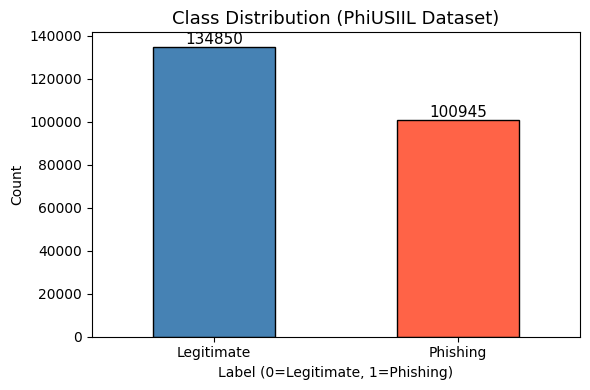

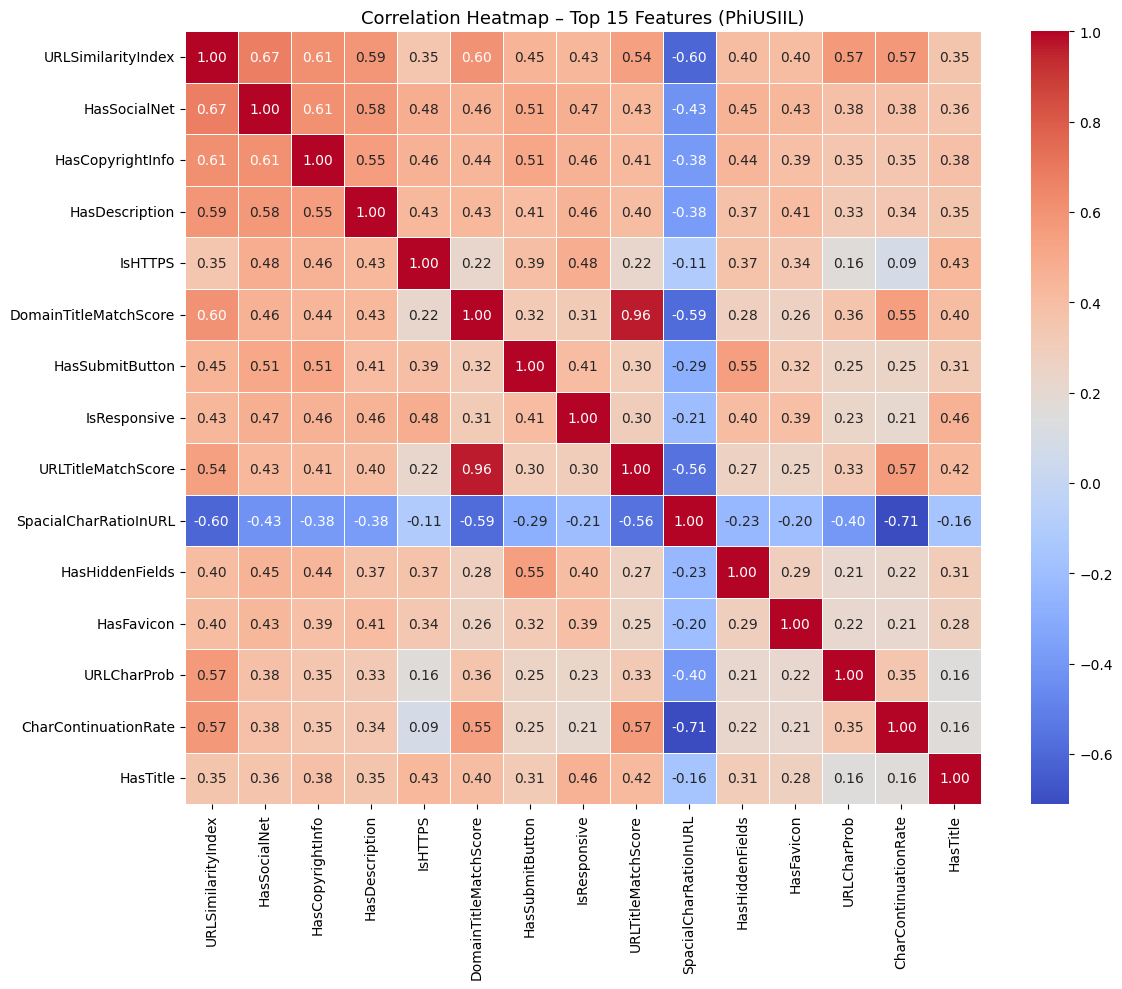

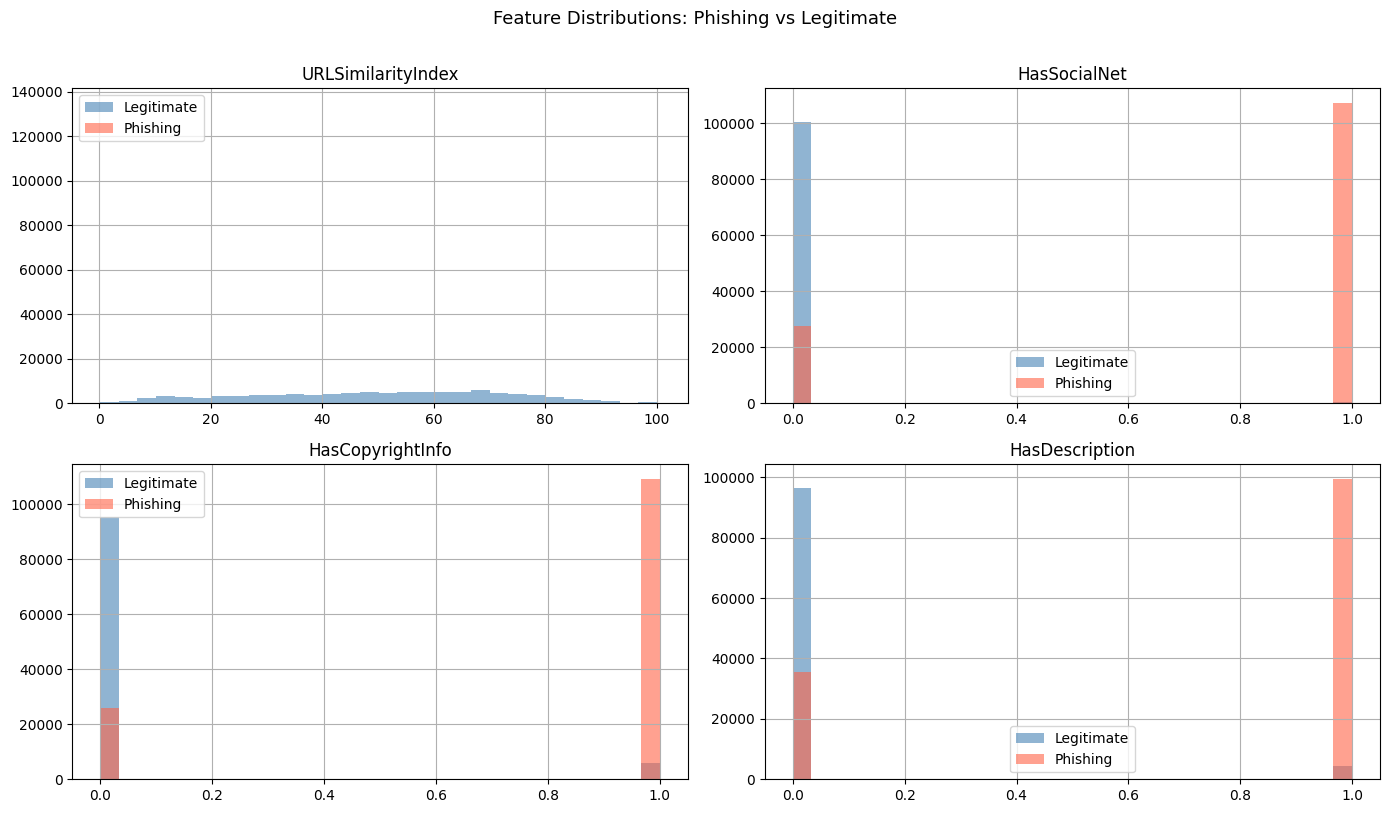

In [ ]:
# ─── BLOCK 1: EDA Visualizations ───────────────────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns

# 1a. Class Distribution
plt.figure(figsize=(6, 4))
ax = df['label'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'], edgecolor='black')
ax.set_title('Class Distribution (PhiUSIIL Dataset)', fontsize=13)
ax.set_xlabel('Label (0=Legitimate, 1=Phishing)')
ax.set_ylabel('Count')
ax.set_xticklabels(['Legitimate', 'Phishing'], rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

# 1b. Correlation Heatmap — use only numeric columns
df_numeric = df.select_dtypes(include='number')  # <-- fix: drop any remaining strings

top_features = df_numeric.corr()['label'].abs().sort_values(ascending=False).index[1:16]
plt.figure(figsize=(12, 10))
sns.heatmap(df_numeric[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap – Top 15 Features (PhiUSIIL)', fontsize=13)
plt.tight_layout()
plt.show()

# 1c. Feature Distribution: Phishing vs Legitimate (top 4 features)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, feat in zip(axes.flatten(), top_features[:4]):
    df_numeric[df_numeric['label'] == 0][feat].hist(ax=ax, bins=30, alpha=0.6, label='Legitimate', color='steelblue')
    df_numeric[df_numeric['label'] == 1][feat].hist(ax=ax, bins=30, alpha=0.6, label='Phishing', color='tomato')
    ax.set_title(feat)
    ax.legend()
plt.suptitle('Feature Distributions: Phishing vs Legitimate', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Identify Target Column


In [ ]:
'label'

'label'

In [ ]:
df['label'].value_counts()

,count
label,
1,134850
0,100945


In [ ]:
df = df.drop(['FILENAME', 'URL', 'Domain'], axis=1)

In [ ]:
df.select_dtypes(include='object').columns

Index(['TLD', 'Title'], dtype='object')

In [ ]:
df = df.drop(['TLD', 'Title'], axis=1)

In [ ]:
X = df.drop('label', axis=1)
y = df['label']

In [ ]:
df.isnull().sum()

,0
URLLength,0
DomainLength,0
IsDomainIP,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0
URLCharProb,0
TLDLength,0
NoOfSubDomain,0
HasObfuscation,0


In [ ]:
X = df.drop('label', axis=1)
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model 1: Logistic Regression (raw)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9999575902796921

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     20124
           1       1.00      1.00      1.00     27035

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


Confusion Matrix:
 [[20123     1]
 [    1 27034]]


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Model 2: Logistic Regression (with scaling)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9998303611187684

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     20124
           1       1.00      1.00      1.00     27035

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


Confusion Matrix:
 [[20116     8]
 [    0 27035]]


Strong Model (Random Forest)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     20124
           1       1.00      1.00      1.00     27035

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


Confusion Matrix:
 [[20124     0]
 [    0 27035]]


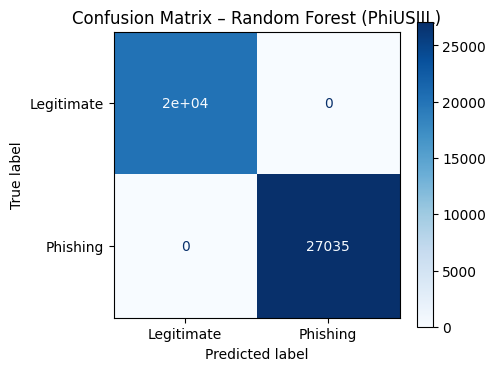

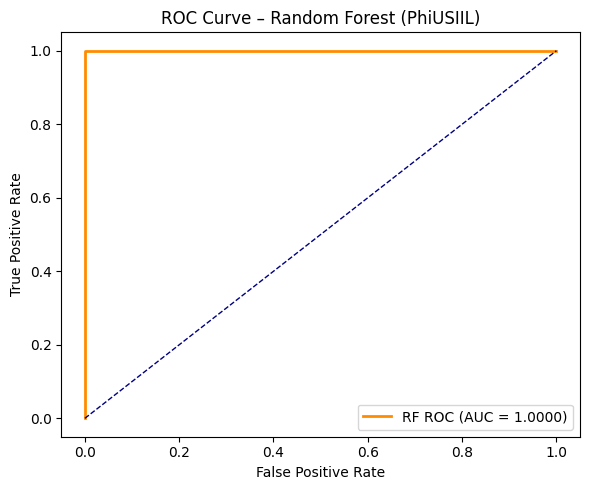

In [ ]:
# ─── BLOCK 2: Confusion Matrix & ROC Curve (RF on PhiUSIIL) ────────────────

from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

# 2a. Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf,
    display_labels=['Legitimate', 'Phishing'],
    cmap='Blues', ax=ax)
ax.set_title('Confusion Matrix – Random Forest (PhiUSIIL)', fontsize=12)
plt.tight_layout()
plt.show()

# 2b. ROC Curve
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'RF ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Random Forest (PhiUSIIL)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Feature Importance Check


In [ ]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance.head(10)

,0
URLSimilarityIndex,0.173672
NoOfExternalRef,0.169276
LineOfCode,0.153836
NoOfSelfRef,0.106813
NoOfImage,0.093526
NoOfJS,0.069344
HasSocialNet,0.033428
NoOfCSS,0.030517
HasCopyrightInfo,0.024518
IsHTTPS,0.021136


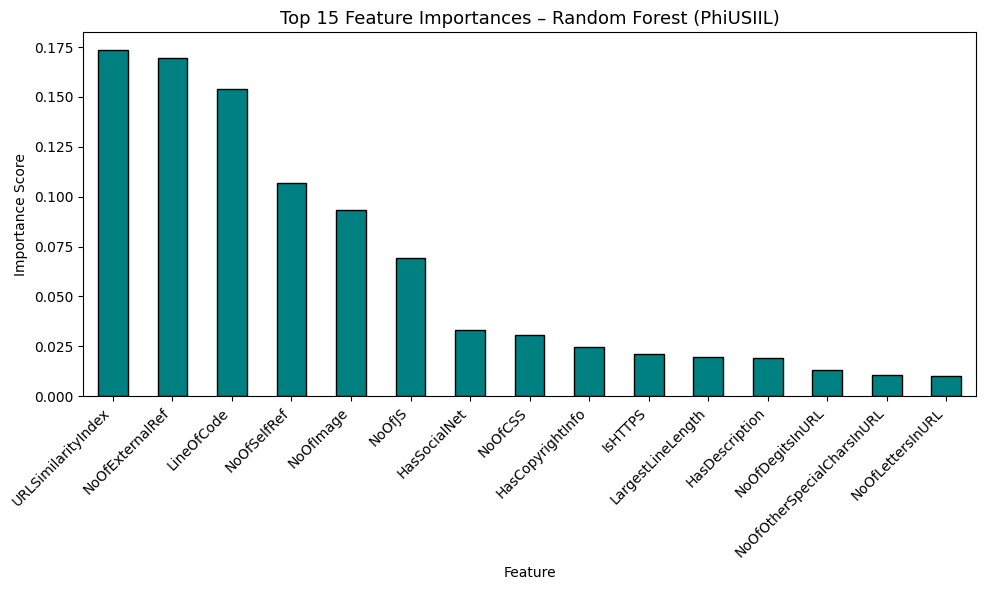

In [ ]:
# ─── BLOCK 3: Feature Importance Bar Chart ──────────────────────────────────

top_n = 15
fi = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
fi.head(top_n).plot(kind='bar', color='teal', edgecolor='black')
plt.title(f'Top {top_n} Feature Importances – Random Forest (PhiUSIIL)', fontsize=13)
plt.xlabel('Feature')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
drop_cols = ['URLSimilarityIndex']
df_reduced = df.drop(drop_cols, axis=1)

In [ ]:
X = df_reduced.drop('label', axis=1)
y = df_reduced['label']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.9998727708390763

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     20124
           1       1.00      1.00      1.00     27035

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159


Confusion Matrix:
 [[20120     4]
 [    2 27033]]


“Removing highly influential features such as URLSimilarityIndex resulted in only a minor decrease in performance, indicating the presence of multiple strong predictive features within the dataset.”From your importance list, remove:

URLSimilarityIndex (already removed)
NoOfExternalRef
LineOfCode

In [ ]:
drop_cols = ['URLSimilarityIndex', 'NoOfExternalRef', 'LineOfCode']
df_reduced2 = df.drop(drop_cols, axis=1)

In [ ]:
X = df_reduced2.drop('label', axis=1)
y = df_reduced2['label']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.9997879513984606

Confusion Matrix:
 [[20118     6]
 [    4 27031]]


Train with new dataset


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/Group_08_CSE437_Project/dataset.csv'
df_train = pd.read_csv(file_path)

df_train = df_train.drop('id', axis=1)

print("Before mapping:")
print(df_train['Result'].value_counts())

df_train['Result'] = df_train['Result'].map({-1: 1, 1: 0})

print("After mapping:")
print(df_train['Result'].value_counts())

print("Missing labels:", df_train['Result'].isnull().sum())

Before mapping:
Result
 1    6157
-1    4898
Name: count, dtype: int64
After mapping:
Result
0    6157
1    4898
Name: count, dtype: int64
Missing labels: 0


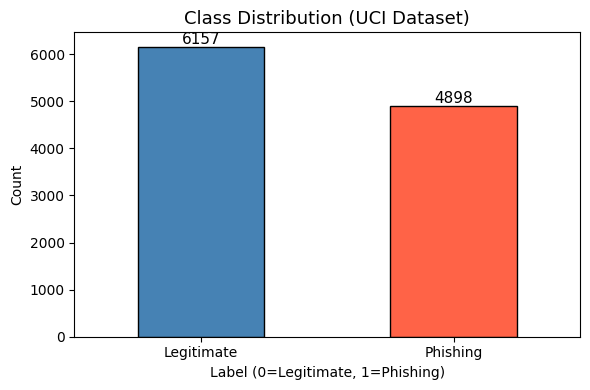

=== UCI Dataset – Descriptive Statistics ===
                               count      mean       std  min  25%  50%  75%  max
having_IP_Address            11055.0  0.313795  0.949534 -1.0 -1.0  1.0  1.0  1.0
URL_Length                   11055.0 -0.633198  0.766095 -1.0 -1.0 -1.0 -1.0  1.0
Shortining_Service           11055.0  0.738761  0.673998 -1.0  1.0  1.0  1.0  1.0
having_At_Symbol             11055.0  0.700588  0.713598 -1.0  1.0  1.0  1.0  1.0
double_slash_redirecting     11055.0  0.741474  0.671011 -1.0  1.0  1.0  1.0  1.0
Prefix_Suffix                11055.0 -0.734962  0.678139 -1.0 -1.0 -1.0 -1.0  1.0
having_Sub_Domain            11055.0  0.063953  0.817518 -1.0 -1.0  0.0  1.0  1.0
SSLfinal_State               11055.0  0.250927  0.911892 -1.0 -1.0  1.0  1.0  1.0
Domain_registeration_length  11055.0 -0.336771  0.941629 -1.0 -1.0 -1.0  1.0  1.0
Favicon                      11055.0  0.628584  0.777777 -1.0  1.0  1.0  1.0  1.0
port                         11055.0  0.728268  0.685

In [ ]:
# ─── BLOCK 4: UCI Dataset – Class Distribution & Descriptive Statistics ─────

# 4a. Class Distribution
plt.figure(figsize=(6, 4))
ax = df_train['Result'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'], edgecolor='black')
ax.set_title('Class Distribution (UCI Dataset)', fontsize=13)
ax.set_xlabel('Label (0=Legitimate, 1=Phishing)')
ax.set_ylabel('Count')
ax.set_xticklabels(['Legitimate', 'Phishing'], rotation=0)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

# 4b. Descriptive Statistics Table
print("=== UCI Dataset – Descriptive Statistics ===")
print(df_train.describe().T.to_string())

In [ ]:
X_train_uc = df_train.drop('Result', axis=1)
y_train_uc = df_train['Result']

In [ ]:
from sklearn.model_selection import train_test_split

X_train_uc_split, X_test_uc, y_train_uc_split, y_test_uc = train_test_split(
    X_train_uc,
    y_train_uc,
    test_size=0.2,
    random_state=42,
    stratify=y_train_uc
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model_uc = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_uc.fit(X_train_uc_split, y_train_uc_split)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_uc = rf_model_uc.predict(X_test_uc)

print("UCI Accuracy:", accuracy_score(y_test_uc, y_pred_uc))
print("\nClassification Report:\n", classification_report(y_test_uc, y_pred_uc))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_uc, y_pred_uc))

UCI Accuracy: 0.9751243781094527

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.98      1231
           1       0.98      0.96      0.97       980

    accuracy                           0.98      2211
   macro avg       0.98      0.97      0.97      2211
weighted avg       0.98      0.98      0.98      2211


Confusion Matrix:
 [[1211   20]
 [  35  945]]


XGBoost (UCI dataset)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_uc_split, y_train_uc_split)

y_pred_xgb = xgb_model.predict(X_test_uc)

print("XGBoost Accuracy:", accuracy_score(y_test_uc, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test_uc, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_uc, y_pred_xgb))

XGBoost Accuracy: 0.9624604251469923

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97      1231
           1       0.96      0.95      0.96       980

    accuracy                           0.96      2211
   macro avg       0.96      0.96      0.96      2211
weighted avg       0.96      0.96      0.96      2211


Confusion Matrix:
 [[1197   34]
 [  49  931]]


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [21:10:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Hybrid Model (Strong Version)

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

lr = LogisticRegression(max_iter=2000)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

hybrid_model = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('rf', rf),
        ('xgb', xgb)
    ],
    voting='soft'
)

hybrid_model.fit(X_train_uc_split, y_train_uc_split)

y_pred_hybrid = hybrid_model.predict(X_test_uc)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Hybrid Accuracy:", accuracy_score(y_test_uc, y_pred_hybrid))
print("\nClassification Report:\n", classification_report(y_test_uc, y_pred_hybrid))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_uc, y_pred_hybrid))

Hybrid Accuracy: 0.9651741293532339

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97      1231
           1       0.97      0.95      0.96       980

    accuracy                           0.97      2211
   macro avg       0.97      0.96      0.96      2211
weighted avg       0.97      0.97      0.97      2211


Confusion Matrix:
 [[1203   28]
 [  49  931]]


Stacking Hybrid

In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('xgb', XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42))
]

stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    passthrough=False
)

stack_model.fit(X_train_uc_split, y_train_uc_split)

y_pred_stack = stack_model.predict(X_test_uc)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Stacking Accuracy:", accuracy_score(y_test_uc, y_pred_stack))
print("\nClassification Report:\n", classification_report(y_test_uc, y_pred_stack))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_uc, y_pred_stack))

Stacking Accuracy: 0.9764812302125735

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.98      0.98      1231
           1       0.98      0.97      0.97       980

    accuracy                           0.98      2211
   macro avg       0.98      0.98      0.98      2211
weighted avg       0.98      0.98      0.98      2211


Confusion Matrix:
 [[1210   21]
 [  31  949]]


=== Model Performance Comparison (UCI Dataset) ===
                 Accuracy  Precision  Recall  F1-Score
Model                                                 
Random Forest      0.9751     0.9793  0.9643    0.9717
XGBoost            0.9625     0.9648  0.9500    0.9573
Voting Hybrid      0.9652     0.9708  0.9500    0.9603
Stacking Hybrid    0.9765     0.9784  0.9684    0.9733


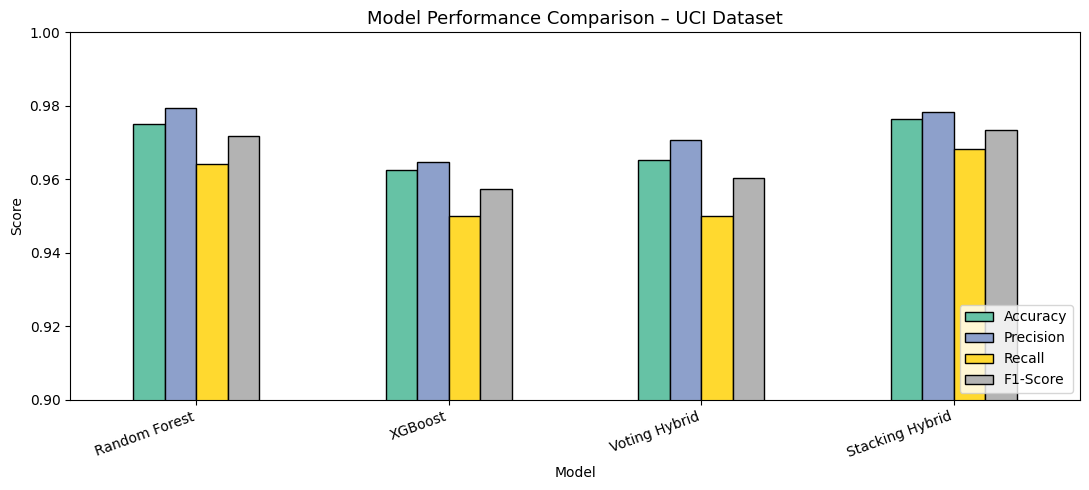

In [ ]:
# ─── BLOCK 5: Model Comparison Summary ──────────────────────────────────────

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models_results = {
    'Random Forest':   y_pred_uc,
    'XGBoost':         y_pred_xgb,
    'Voting Hybrid':   y_pred_hybrid,
    'Stacking Hybrid': y_pred_stack,
}

rows = []
for name, preds in models_results.items():
    rows.append({
        'Model':     name,
        'Accuracy':  accuracy_score(y_test_uc, preds),
        'Precision': precision_score(y_test_uc, preds),
        'Recall':    recall_score(y_test_uc, preds),
        'F1-Score':  f1_score(y_test_uc, preds),
    })

comparison_df = pd.DataFrame(rows).set_index('Model')
print("=== Model Performance Comparison (UCI Dataset) ===")
print(comparison_df.to_string(float_format='{:.4f}'.format))

# Bar chart
comparison_df.plot(kind='bar', figsize=(11, 5), edgecolor='black', colormap='Set2')
plt.title('Model Performance Comparison – UCI Dataset', fontsize=13)
plt.ylabel('Score')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

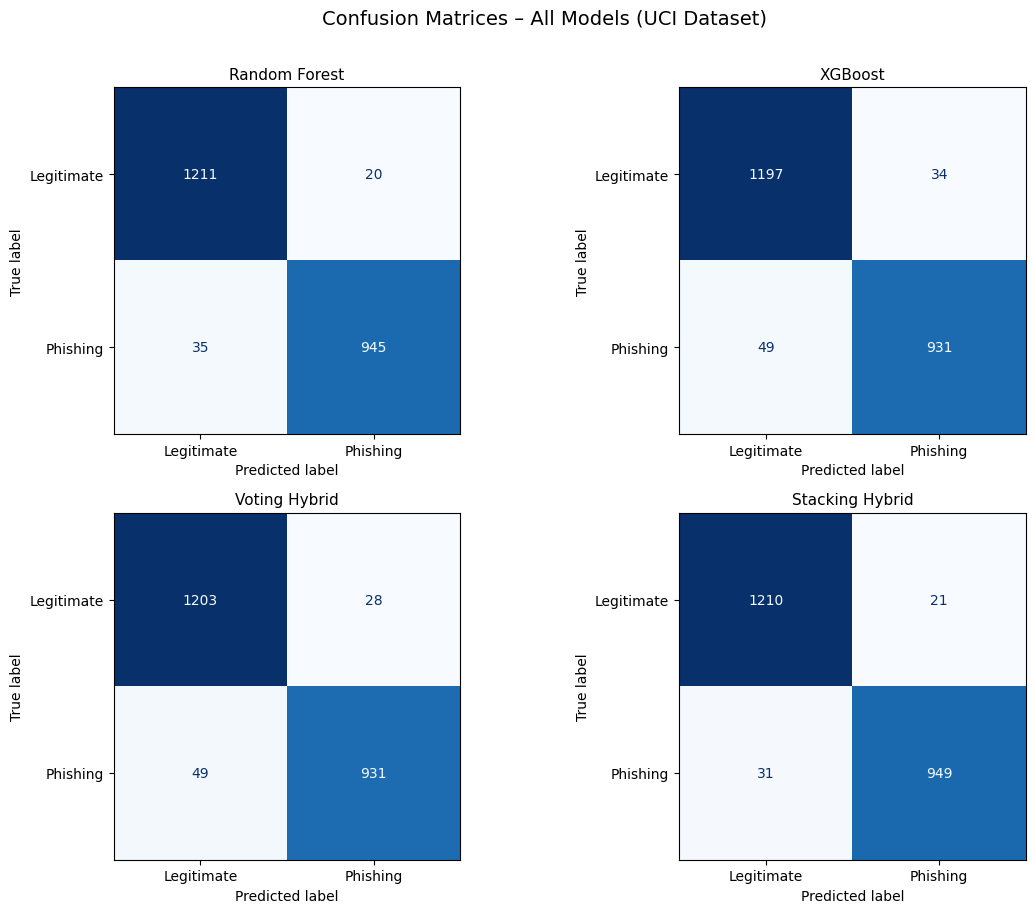

In [ ]:
# ─── BLOCK 6: Confusion Matrix Grid ─────────────────────────────────────────

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, preds) in zip(axes.flatten(), models_results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_uc, preds,
        display_labels=['Legitimate', 'Phishing'],
        cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name, fontsize=11)
plt.suptitle('Confusion Matrices – All Models (UCI Dataset)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

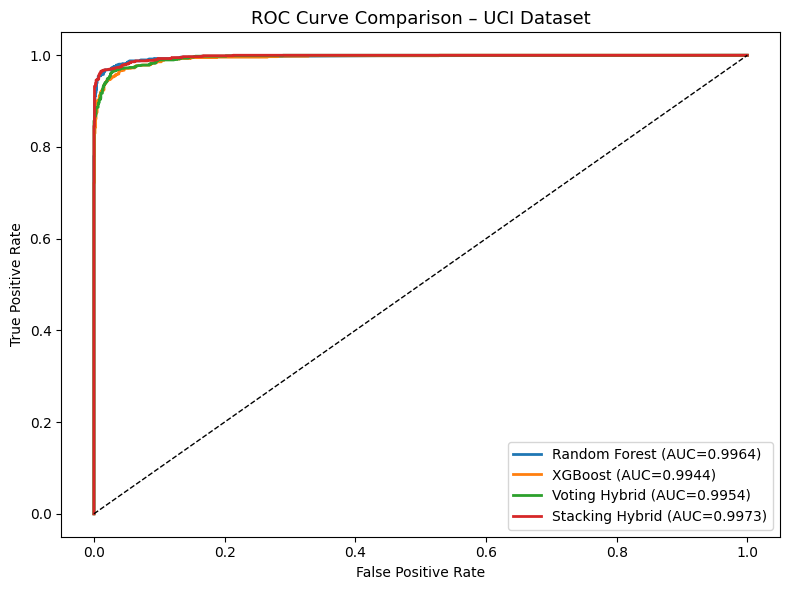

In [ ]:
# ─── BLOCK 7: ROC Curve Comparison ──────────────────────────────────────────

from sklearn.metrics import roc_curve, auc

prob_models = {
    'Random Forest':   rf_model_uc.predict_proba(X_test_uc)[:, 1],
    'XGBoost':         xgb_model.predict_proba(X_test_uc)[:, 1],
    'Voting Hybrid':   hybrid_model.predict_proba(X_test_uc)[:, 1],
    'Stacking Hybrid': stack_model.predict_proba(X_test_uc)[:, 1],
}

plt.figure(figsize=(8, 6))
for name, probs in prob_models.items():
    fpr, tpr, _ = roc_curve(y_test_uc, probs)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc(fpr, tpr):.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison – UCI Dataset', fontsize=13)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Explainability (SHAP)

In [ ]:
!pip install shap

In [ ]:
import shap

explainer = shap.TreeExplainer(rf_model_uc)
shap_values = explainer.shap_values(X_test_uc)

print(type(shap_values))
print(len(shap_values) if isinstance(shap_values, list) else shap_values.shape)

<class 'numpy.ndarray'>
(2211, 30, 2)


(2211, 30)
(2211, 30)


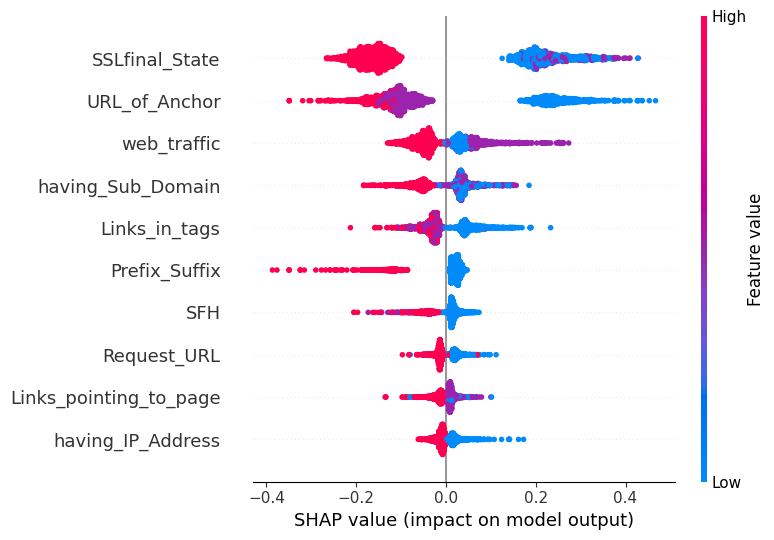

In [ ]:
shap_class_1 = shap_values[:, :, 1]

print(shap_class_1.shape)
print(X_test_uc.shape)

shap.summary_plot(shap_class_1, X_test_uc, max_display=10)

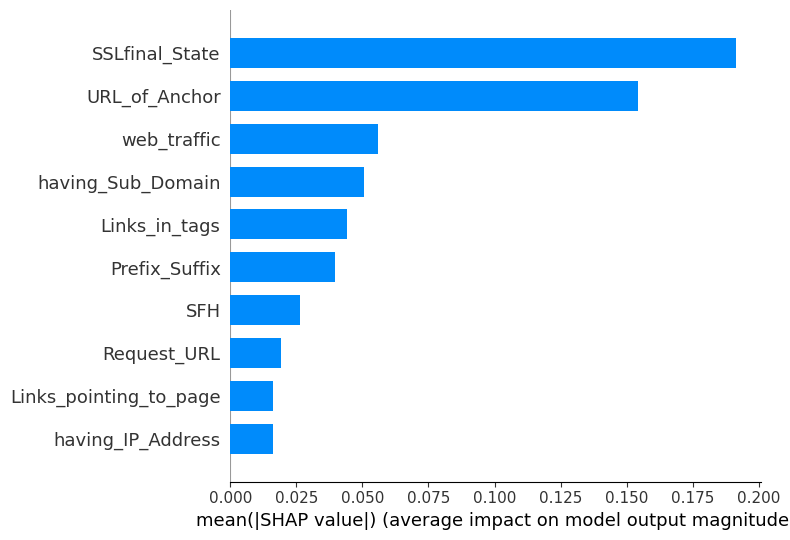

In [ ]:
shap.summary_plot(shap_class_1, X_test_uc, plot_type="bar", max_display=10)

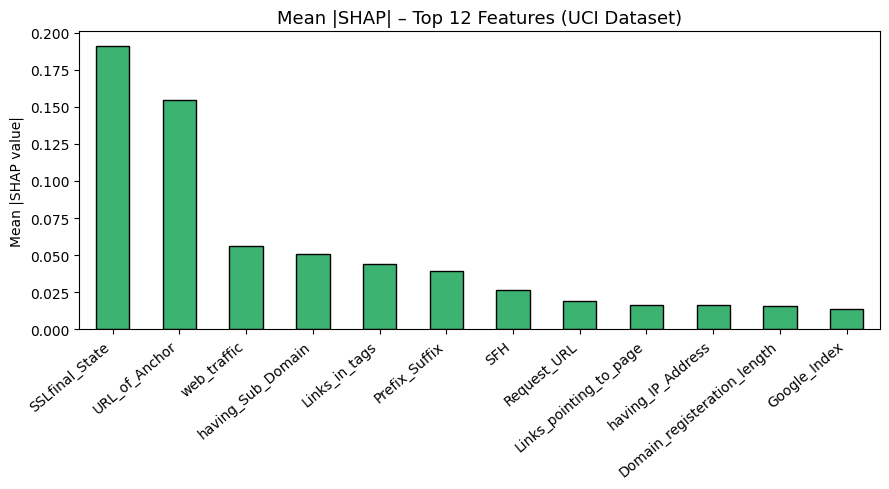

In [ ]:
# ─── BLOCK 8: SHAP Mean Bar Chart ───────────────────────────────────────────
import numpy as np

# Mean absolute SHAP per feature (reusing shap_class_1 already computed above)
mean_shap = pd.Series(
    np.abs(shap_class_1).mean(axis=0),
    index=X_test_uc.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
mean_shap.head(12).plot(kind='bar', color='mediumseagreen', edgecolor='black')
plt.title('Mean |SHAP| – Top 12 Features (UCI Dataset)', fontsize=13)
plt.ylabel('Mean |SHAP value|')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

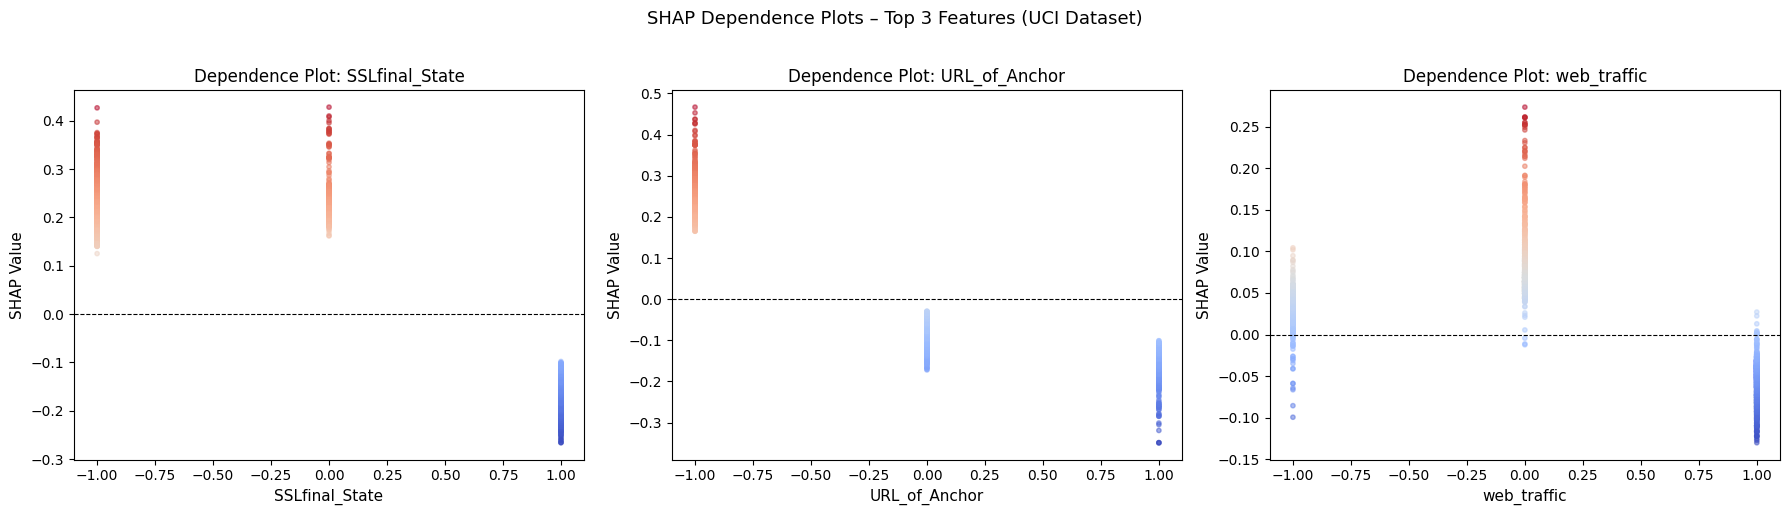

In [ ]:
# ─── BLOCK 9: SHAP Dependence Plots – Top 3 Features ────────────────────────

top3_features = mean_shap.head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feat in zip(axes, top3_features):
    feat_idx = list(X_test_uc.columns).index(feat)

    ax.scatter(
        X_test_uc[feat],
        shap_class_1[:, feat_idx],
        c=shap_class_1[:, feat_idx],
        cmap='coolwarm',
        alpha=0.5,
        s=10
    )
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xlabel(feat, fontsize=11)
    ax.set_ylabel('SHAP Value', fontsize=11)
    ax.set_title(f'Dependence Plot: {feat}', fontsize=12)

plt.suptitle('SHAP Dependence Plots – Top 3 Features (UCI Dataset)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()